# Data leakage on the UCI voice data
*Screening support, not diagnosis.* The same models, evaluated with a recording-level random split vs. a subject-wise split. Each person has 6-7 recordings, so a random split lets the model see a person's voice in training and then "predict" that same person in testing.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.voice.load import load_voice, get_xyg, subject_summary
from src.voice.models import factory
from src.splits import make_splits, assert_disjoint_groups
from src.evaluate import repeated_oof, summarize_repeats
df = load_voice(); X, y, g = get_xyg(df)
print(subject_summary(df))

{'n_recordings': 195, 'n_subjects': 32, 'subjects_per_class': {0: 8, 1: 24}, 'recordings_per_class': {0: 48, 1: 147}, 'recordings_per_subject_min_max': [6, 7], 'subjects_with_mixed_labels': 0}


In [2]:
sp = make_splits('random', y, g, 42)
print('subjects present in BOTH train and test, per random fold:', [len(set(g[a]) & set(g[b])) for a, b in sp])
assert_disjoint_groups(g, make_splits('group', y, g, 42)); print('group split: no overlap (verified)')

subjects present in BOTH train and test, per random fold: [25, 26, 23, 26, 23]
group split: no overlap (verified)


In [3]:
rows=[]
for name in ['logreg','random_forest']:
    for kind in ['random','group']:
        P = repeated_oof(factory(name), X, y, g, kind, [42+i for i in range(5)])
        s = summarize_repeats(y, P)
        rows.append(dict(model=name, split=kind, bal_acc=s['balanced_accuracy'][0], bal_acc_sd=s['balanced_accuracy'][1], auc=s['roc_auc'][0], auc_sd=s['roc_auc'][1]))
res = pd.DataFrame(rows).round(3); res

,model,split,bal_acc,bal_acc_sd,auc,auc_sd
0,logreg,random,0.769,0.016,0.897,0.004
1,logreg,group,0.658,0.013,0.770,0.027
2,random_forest,random,0.832,0.012,0.950,0.008
3,random_forest,group,0.634,0.013,0.792,0.015


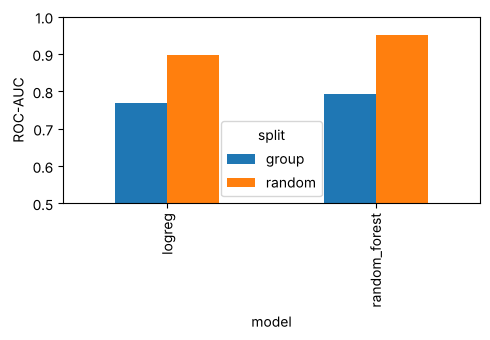

In [4]:
fig, ax = plt.subplots(figsize=(5,3.5))
piv = res.pivot(index='model', columns='split', values='auc'); piv.plot.bar(ax=ax); ax.set_ylabel('ROC-AUC'); ax.set_ylim(0.5,1); plt.tight_layout(); plt.show()

**Reading it:** the gap between the two bars is leakage, not skill. Full results (4 models, LOSO, bootstrap CIs) are in `experiments/results/voice/leakage_results.csv`.